<a href="https://colab.research.google.com/github/kumarchoubeyaaush-cpu/Data-Science-Lab-1/blob/main/Data_Aggregation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Date : 24/11/2026

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("/content/weather_by_cities.csv")

In [3]:
df

,day,city,temperature,windspeed,event
0,1/1/2017,new york,32,6,Rain
1,1/2/2017,new york,36,7,Sunny
2,1/3/2017,new york,28,12,Snow
3,1/4/2017,new york,33,7,Sunny
4,1/1/2017,mumbai,90,5,Sunny
5,1/2/2017,mumbai,85,12,Fog
6,1/3/2017,mumbai,87,15,Fog
7,1/4/2017,mumbai,92,5,Rain
8,1/1/2017,paris,45,20,Sunny
9,1/2/2017,paris,50,13,Cloudy


# **Group By**

---



In [4]:
g=df.groupby("city")

In [5]:
g

In [8]:
for city ,data in g:
  print("City",city)
  print("\n")
  print("data",data)

City mumbai


data         day    city  temperature  windspeed  event
4  1/1/2017  mumbai           90          5  Sunny
5  1/2/2017  mumbai           85         12    Fog
6  1/3/2017  mumbai           87         15    Fog
7  1/4/2017  mumbai           92          5   Rain
City new york


data         day      city  temperature  windspeed  event
0  1/1/2017  new york           32          6   Rain
1  1/2/2017  new york           36          7  Sunny
2  1/3/2017  new york           28         12   Snow
3  1/4/2017  new york           33          7  Sunny
City paris


data          day   city  temperature  windspeed   event
8   1/1/2017  paris           45         20   Sunny
9   1/2/2017  paris           50         13  Cloudy
10  1/3/2017  paris           54          8  Cloudy
11  1/4/2017  paris           42         10  Cloudy


In [9]:
g.max()

,day,temperature,windspeed,event
city,,,,
mumbai,1/4/2017,92,15,Sunny
new york,1/4/2017,36,12,Sunny
paris,1/4/2017,54,20,Sunny


In [10]:
g.min()

,day,temperature,windspeed,event
city,,,,
mumbai,1/1/2017,85,5,Fog
new york,1/1/2017,28,6,Rain
paris,1/1/2017,42,8,Cloudy


In [12]:
g.mean(numeric_only=True)

,temperature,windspeed
city,,
mumbai,88.50,9.25
new york,32.25,8.00
paris,47.75,12.75


In [13]:
g.describe()

temperature                                                   \
               count   mean       std   min    25%   50%    75%   max   
city                                                                    
mumbai           4.0  88.50  3.109126  85.0  86.50  88.5  90.50  92.0   
new york         4.0  32.25  3.304038  28.0  31.00  32.5  33.75  36.0   
paris            4.0  47.75  5.315073  42.0  44.25  47.5  51.00  54.0   

         windspeed                                                 
             count   mean       std  min   25%   50%    75%   max  
city                                                               
mumbai         4.0   9.25  5.057997  5.0  5.00   8.5  12.75  15.0  
new york       4.0   8.00  2.708013  6.0  6.75   7.0   8.25  12.0  
paris          4.0  12.75  5.251984  8.0  9.50  11.5  14.75  20.0

In [16]:
g.size()

,0
city,
mumbai,4
new york,4
paris,4


In [17]:
import matplotlib.pyplot as plt


Text(0.5, 1.0, 'Mean of Temperature')

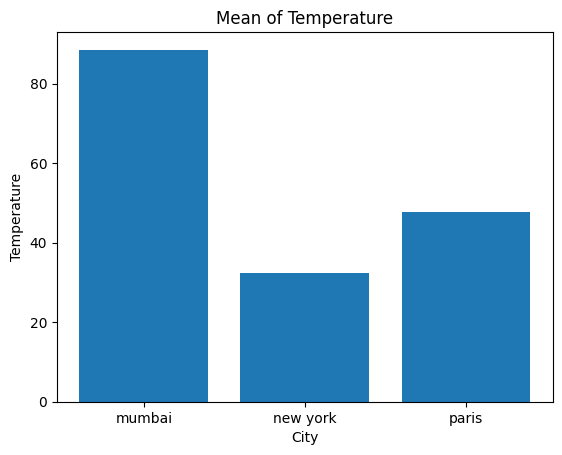

In [21]:
g=df.groupby("city")['temperature'].mean()
plt.bar(g.index,g.values)
plt.xlabel("City")
plt.ylabel("Temperature")
plt.title("Mean of Temperature")


Text(0.5, 1.0, 'Mean of windspeed')

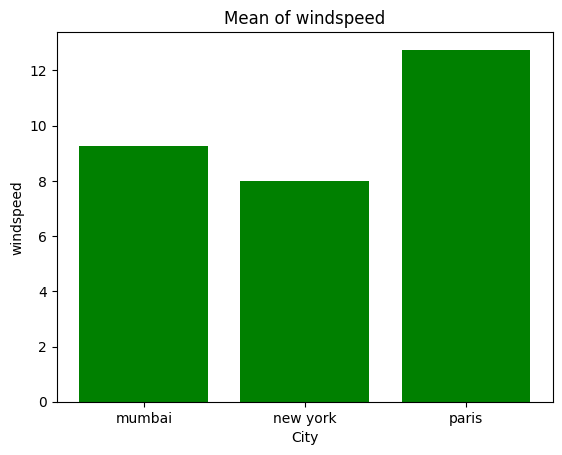

In [29]:
g=df.groupby("city")["windspeed"].mean()
plt.bar(g.index,g,color ='green')
plt.xlabel("City")
plt.ylabel("windspeed")
plt.title("Mean of windspeed")

In [25]:
df1 = df.set_index(["city","day"])
g1=df1.groupby(level=1)['temperature'].mean()

In [26]:
g1.head(30)

,temperature
day,
1/1/2017,55.666667
1/2/2017,57.000000
1/3/2017,56.333333
1/4/2017,55.666667


In [31]:
print(df.groupby("city",as_index=True)["temperature"].mean())

city
mumbai      88.50
new york    32.25
paris       47.75
Name: temperature, dtype: float64


In [32]:
print(df.groupby("city",observed=True)["temperature"].mean())

city
mumbai      88.50
new york    32.25
paris       47.75
Name: temperature, dtype: float64


In [33]:
print(df.groupby("city",dropna=True)["temperature"].mean())

city
mumbai      88.50
new york    32.25
paris       47.75
Name: temperature, dtype: float64


In [34]:
df.aggregate("mean",numeric_only=True)

,0
temperature,56.166667
windspeed,10.000000


In [38]:
df.aggregate({"temperature" : ["min","max","mean"],
              "windspeed" : ["min","max"]
              })

,temperature,windspeed
min,28.000000,5.0
max,92.000000,20.0
mean,56.166667,NaN


In [41]:
df

,day,city,temperature,windspeed,event
0,1/1/2017,new york,32,6,Rain
1,1/2/2017,new york,36,7,Sunny
2,1/3/2017,new york,28,12,Snow
3,1/4/2017,new york,33,7,Sunny
4,1/1/2017,mumbai,90,5,Sunny
5,1/2/2017,mumbai,85,12,Fog
6,1/3/2017,mumbai,87,15,Fog
7,1/4/2017,mumbai,92,5,Rain
8,1/1/2017,paris,45,20,Sunny
9,1/2/2017,paris,50,13,Cloudy


In [40]:
df[["temperature","windspeed"]].aggregate("sum",axis=1)

,0
0,38
1,43
2,40
3,40
4,95
5,97
6,102
7,97
8,65
9,63


In [42]:
df[["temperature","windspeed"]].aggregate("sum")

,0
temperature,674
windspeed,120


In [43]:
df

,day,city,temperature,windspeed,event
0,1/1/2017,new york,32,6,Rain
1,1/2/2017,new york,36,7,Sunny
2,1/3/2017,new york,28,12,Snow
3,1/4/2017,new york,33,7,Sunny
4,1/1/2017,mumbai,90,5,Sunny
5,1/2/2017,mumbai,85,12,Fog
6,1/3/2017,mumbai,87,15,Fog
7,1/4/2017,mumbai,92,5,Rain
8,1/1/2017,paris,45,20,Sunny
9,1/2/2017,paris,50,13,Cloudy


In [44]:
table=df.pivot_table(
                        values="temperature",
                        index="city",
                        aggfunc="mean"
)
print(table)

          temperature
city                 
mumbai          88.50
new york        32.25
paris           47.75


In [46]:
table=df.pivot_table(
                        values=["temperature","windspeed"],
                        index="city",
                        columns="day"
)
print(table)

         temperature                            windspeed                    \
day         1/1/2017 1/2/2017 1/3/2017 1/4/2017  1/1/2017 1/2/2017 1/3/2017   
city                                                                          
mumbai          90.0     85.0     87.0     92.0       5.0     12.0     15.0   
new york        32.0     36.0     28.0     33.0       6.0      7.0     12.0   
paris           45.0     50.0     54.0     42.0      20.0     13.0      8.0   

                   
day      1/4/2017  
city               
mumbai        5.0  
new york      7.0  
paris        10.0  


In [47]:
table=df.pivot_table(
                        values=["temperature","windspeed"],
                        index="city",
                       aggfunc="max"
)
print(table)

          temperature  windspeed
city                            
mumbai             92         15
new york           36         12
paris              54         20


In [48]:
table=df.pivot_table(
                        values=["temperature","windspeed"],
                        index="city",
                       aggfunc="sum"
)
print(table)

          temperature  windspeed
city                            
mumbai            354         37
new york          129         32
paris             191         51


In [50]:
table=df.pivot_table(
                        values=["temperature","windspeed"],
                        index="city",
                       aggfunc=["max","min","mean"]
)
print(table)

                 max                   min                  mean          
         temperature windspeed temperature windspeed temperature windspeed
city                                                                      
mumbai            92        15          85         5       88.50      9.25
new york          36        12          28         6       32.25      8.00
paris             54        20          42         8       47.75     12.75
